In [1]:
import matplotlib.pyplot as plt
import pandas as pd

data_dir = "../input/ts-course-data"

store_sales = pd.read_csv(
    '../datasets/store-sales-time-series-forecasting/train.csv',
    usecols=['store_nbr', 'family', 'date', 'sales', 'onpromotion'],
    dtype={
        'store_nbr': 'category',
        'family': 'category',
        'sales': 'float32',
    },
    parse_dates=['date']
)
store_sales['date'] = store_sales.date.dt.to_period('D')
store_sales = store_sales.set_index(['store_nbr', 'family', 'date']).sort_index()

family_sales = (
    store_sales
    .groupby(['family', 'date'], observed=False)
    .mean()
    .unstack('family')
    .loc['2017']
)

In [2]:
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

class BoostedHybrid:
    def __init__(self, model_1, model_2):
        self.model_1 = model_1
        self.model_2 = model_2
        self.y_columns = None

In [3]:
def fit(self, X_1, X_2, y):
    # fit self.model_1
    self.model_1.fit(X_1, y)

    y_fit = pd.DataFrame(
        # make predictions with self.model_1
        self.model_1.predict(X_1),
        index=X_1.index, columns=y.columns,
    )

    # compute residuals
    y_resid = y - y_fit
    y_resid = y_resid.stack().squeeze()

    # fit self.model_2 on residuals
    self.model_2.fit(X_2, y_resid)

    # Save column names for predict method
    self.y_columns = y.columns
    
    # Save data for question checking
    self.y_fit = y_fit
    self.y_resid = y_resid

BoostedHybrid.fit = fit

In [4]:
def predict(self, X_1, X_2):
    y_pred = pd.DataFrame(
        # predict with self.model_1
        self.model_1.predict(X_1),
        index=X_1.index, columns=self.y_columns,
    )
    y_pred = y_pred.stack().squeeze()

    # add self.model_2 predictions to y_pred
    y_pred += self.model_2.predict(X_2)
    
    return y_pred.unstack()

BoostedHybrid.predict = predict

In [5]:
from sklearn.preprocessing import LabelEncoder
from statsmodels.tsa.deterministic import DeterministicProcess

# Target series
y = family_sales.loc[:, 'sales']

# X_1: Features for Linear Regression
dp = DeterministicProcess(index=y.index, order=1)
X_1 = dp.in_sample()

# X_2: Features for XGBoost
X_2 = family_sales.drop('sales', axis=1).stack(future_stack=True)  # onpromotion feature

# Label encoding for 'family'
le = LabelEncoder()
X_2 = X_2.reset_index('family')
X_2['family'] = le.fit_transform(X_2['family'])

# Label encoding for seasonality
X_2["day"] = X_2.index.day  # values are day of the month

In [6]:
# Create LinearRegression + XGBRegressor hybrid with BoostedHybrid
model = BoostedHybrid(LinearRegression(), XGBRegressor(random_state=0))

# Fit and predict
model.fit(X_1, X_2, y)
y_pred = model.predict(X_1, X_2)
y_pred = y_pred.clip(0.0)

In [25]:
# Model 1 (trend)
from sklearn.linear_model import ElasticNet, Lasso, Ridge

# Model 2
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

# Try different combinations of the algorithms above
# Some of the algorithms above do best with certain kinds of preprocessing on the features (like standardization)
model = BoostedHybrid(
    model_1=ElasticNet(),
    model_2=KNeighborsRegressor(),
)

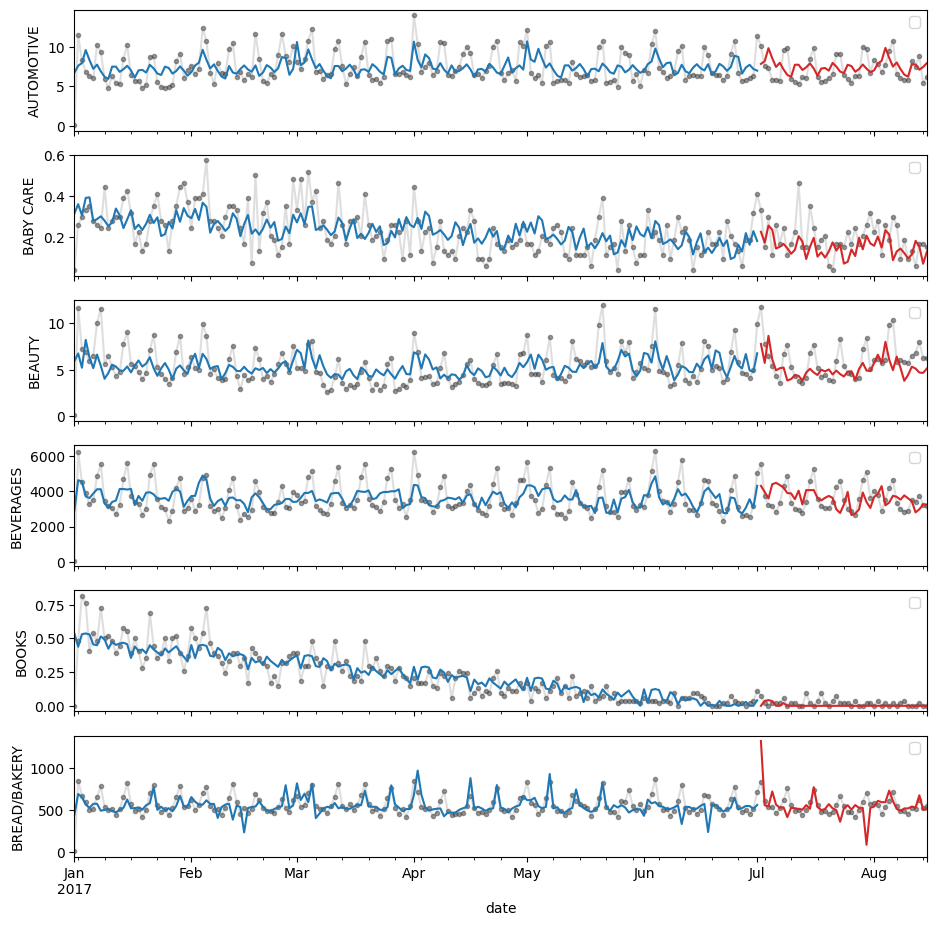

In [26]:
plot_params = {
    'color': '0.75', 
    'style': '.-', 
    'markeredgecolor': '0.25', 
    'markerfacecolor': '0.25', 
    'legend': False
}

y_train, y_valid = y[:"2017-07-01"], y["2017-07-02":]
X1_train, X1_valid = X_1[: "2017-07-01"], X_1["2017-07-02" :]
X2_train, X2_valid = X_2.loc[:"2017-07-01"], X_2.loc["2017-07-02":]

model.fit(X1_train, X2_train, y_train)
y_fit = model.predict(X1_train, X2_train).clip(0.0)
y_pred = model.predict(X1_valid, X2_valid).clip(0.0)

families = y.columns[0:6]
axs = y.loc(axis=1)[families].plot(
    subplots=True, sharex=True, figsize=(11, 11), **plot_params, alpha=0.5,
)
_ = y_fit.loc(axis=1)[families].plot(subplots=True, color='C0', ax=axs)
_ = y_pred.loc(axis=1)[families].plot(subplots=True, color='C3', ax=axs)
for ax, family in zip(axs, families):
    ax.legend([])
    ax.set_ylabel(family)